In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [14]:
file_path = '../data/raw/Inc5000_Company_List_2014.csv'

#leer el archivo csv
df = pd.read_csv(file_path)

In [15]:
#Leer las primeras 5 filas
print(df.head())

   _input  _num           _widgetName               _source  _resultNumber  \
0     NaN     1  Inc5000 Company List  Inc5000 Company List              1   
1     NaN     2  Inc5000 Company List  Inc5000 Company List              2   
2     NaN     3  Inc5000 Company List  Inc5000 Company List              3   
3     NaN     4  Inc5000 Company List  Inc5000 Company List              4   
4     NaN     5  Inc5000 Company List  Inc5000 Company List              5   

                                            _pageUrl     id  rank  workers  \
0  http://www.inc.com/inc5000list/json/inc5000_20...  22890     1      227   
1  http://www.inc.com/inc5000list/json/inc5000_20...  25747     2      191   
2  http://www.inc.com/inc5000list/json/inc5000_20...  25643     3      145   
3  http://www.inc.com/inc5000list/json/inc5000_20...  26098     4       62   
4  http://www.inc.com/inc5000list/json/inc5000_20...  26182     5       92   

                    company                       url        s

In [16]:
#conocer las dimensiones del dataset
print(f'Dataset dimentions (rows, columns): {df.shape}')

#nombres de las columnas disponibles
print(f'\nAvailable columns')
print(f'Columns: {df.columns.tolist()}')

Dataset dimentions (rows, columns): (5000, 19)

Available columns
Columns: ['_input', '_num', '_widgetName', '_source', '_resultNumber', '_pageUrl', 'id', 'rank', 'workers', 'company', 'url', 'state_l', 'state_s', 'city', 'metro', 'growth', 'revenue', 'industry', 'yrs_on_list']


In [17]:
#determinar los tipos de datos (str, int, etc)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   _input         0 non-null      float64
 1   _num           5000 non-null   int64  
 2   _widgetName    5000 non-null   str    
 3   _source        5000 non-null   str    
 4   _resultNumber  5000 non-null   int64  
 5   _pageUrl       5000 non-null   str    
 6   id             5000 non-null   int64  
 7   rank           5000 non-null   int64  
 8   workers        5000 non-null   int64  
 9   company        5000 non-null   str    
 10  url            5000 non-null   str    
 11  state_l        5000 non-null   str    
 12  state_s        5000 non-null   str    
 13  city           5000 non-null   str    
 14  metro          4942 non-null   str    
 15  growth         5000 non-null   float64
 16  revenue        5000 non-null   int64  
 17  industry       5000 non-null   str    
 18  yrs_on_list    5000

In [18]:
#revisar estadisticas del dataset
print('\nStadistics: ')
df.describe()


Stadistics: 


,_input,_num,_resultNumber,id,rank,workers,growth,revenue,yrs_on_list
count,0.0,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03,5000.000000
mean,NaN,2500.500000,2500.500000,20036.575400,2500.500000,208.969800,516.439892,4.305818e+07,2.744400
std,NaN,1443.520003,1443.520003,8041.042917,1443.520003,1074.600125,2786.061791,1.818559e+08,1.999067
min,NaN,1.000000,1.000000,4.000000,1.000000,0.000000,42.447000,1.953000e+06,1.000000
25%,NaN,1250.750000,1250.750000,19575.250000,1250.750000,24.000000,84.208250,4.876791e+06,1.000000
50%,NaN,2500.500000,2500.500000,23291.500000,2500.500000,50.000000,151.722800,1.072208e+07,2.000000
75%,NaN,3750.250000,3750.250000,25370.250000,3750.250000,125.000000,347.652825,2.695213e+07,4.000000
max,NaN,5000.000000,5000.000000,26620.000000,5000.000000,34219.000000,158956.910600,5.528203e+09,12.000000


In [19]:
#revisar las categorias de industrias existentes
print(f'\nIndustry categories: {df['industry'].nunique()}')

#ver las empresas por tipo de industria
print('\nEnterprises: ')
df['industry'].value_counts()


Industry categories: 25

Enterprises: 


industry
IT Services                     733
Advertising & Marketing         453
Business Products & Services    435
Health                          377
Software                        338
Financial Services              278
Consumer Products & Services    230
Government Services             212
Manufacturing                   212
Retail                          200
Human Resources                 199
Construction                    198
Telecommunications              135
Food & Beverage                 132
Logistics & Transportation      132
Real Estate                     131
Energy                          116
Education                        78
Security                         68
Insurance                        67
Engineering                      66
Travel & Hospitality             62
Media                            60
Environmental Services           54
Computer Hardware                34
Name: count, dtype: int64

In [20]:
#revisar valores únicos de algunas columnas
print("\nStates:", df["state_s"].nunique())
print("Cities:", df["city"].nunique())
print("Companies:", df["company"].nunique())


States: 51
Cities: 1352
Companies: 5000


In [21]:
#suma de valores nulos
print(f'Sum null values: {df.isnull().sum()}')

#suma duplicate rows
print(f'\nDuplicate rows: {df.duplicated().sum()}')

#suma de id duplicados
print(f'\nDuplicate IDs: {df["id"].duplicated().sum()}')

Sum null values: _input           5000
_num                0
_widgetName         0
_source             0
_resultNumber       0
_pageUrl            0
id                  0
rank                0
workers             0
company             0
url                 0
state_l             0
state_s             0
city                0
metro              58
growth              0
revenue             0
industry            0
yrs_on_list         0
dtype: int64

Duplicate rows: 0

Duplicate IDs: 0


In [22]:
#identificar las empresas de mayor crecimiento
print('Entrepises growth: ')
df.nlargest(10, "growth")[
    ["company", "industry", "growth", "revenue", "workers"]
]

Entrepises growth: 


,company,industry,growth,revenue,workers
0,Fuhu,Consumer Products & Services,158956.9106,195640000,227
1,Quest Nutrition,Food & Beverage,57347.9246,82640563,191
2,Reliant Asset Management,Business Products & Services,55460.1646,85076502,145
3,Superfish,Software,26042.9630,35293000,62
4,Acacia Communications,Telecommunications,20690.4578,77652360,92
5,Provider Power,Energy,19876.5169,137977203,50
6,Crescendo Bioscience,Health,18375.0693,27308000,129
7,Plexus Worldwide,Health,16457.6529,159897088,130
8,Vacasa,Travel & Hospitality,16192.0610,26263454,264
9,Go Energies,Energy,16006.8013,32851754,11


In [23]:
#ver las empresas con mayores ingresos
print('Enterprises revenue: ')
df.nlargest(10, "revenue")[
    ["company", "industry", "growth", "revenue", "workers"]
]

Enterprises revenue: 


,company,industry,growth,revenue,workers
2662,Pacific Union Real Estate,Real Estate,140.9702,5528202691,646
4949,ABC Supply,Construction,44.0068,4911166514,7355
3690,Eco-Energy Global Biofuels,Energy,86.5446,4138790000,109
1982,EnvisionRxOptions,Health,205.4396,3644869906,800
256,Bridger,Energy,1792.1589,3487872233,105
4618,Prime Therapeutics,Health,54.3229,2511716640,3267
4203,Flyers Energy,Energy,67.9592,1977921907,450
3425,Sun Coast Resources,Energy,97.3349,1868964476,1668
3240,Carahsoft Technology,Government Services,106.7126,1724988401,418
3820,TriNet,Human Resources,81.4493,1644275000,1783


In [24]:
#empresas con mayor cantidad de empleados
print('Enterprises workers:')
df.nlargest(10, "workers")[
    ["company", "industry", "growth", "revenue", "workers"]
]

Enterprises workers:


,company,industry,growth,revenue,workers
2304,Universal Services of America,Security,168.9645,802076555,34219
4151,Sutherland Global Services,Business Products & Services,69.6839,771259000,30000
4176,The Seaton Companies,Human Resources,68.8694,587299000,28726
4506,AtWork Group,Human Resources,57.4518,132359522,23689
4222,Infiniti HR,Human Resources,67.4062,151039927,20000
4676,United Service Companies,Business Products & Services,52.4403,135493184,13100
4301,Wingstop,Food & Beverage,64.6707,549910831,12500
2734,Insight Global,IT Services,136.5545,918390882,11561
4575,VXI Global Solutions,Telecommunications,55.6771,249609092,10000
4128,Acro Service,Human Resources,70.3464,215367840,9546


In [26]:
#ingresos promedio por industria
industry_revenue = (
    df.groupby('industry')['revenue'].mean().sort_values(ascending = False)
)

industry_revenue

industry
Energy                          1.862298e+08
Logistics & Transportation      8.491203e+07
Telecommunications              6.916277e+07
Insurance                       6.791500e+07
Real Estate                     6.783643e+07
Human Resources                 6.117810e+07
Travel & Hospitality            5.878591e+07
Health                          5.841612e+07
Construction                    5.223423e+07
Food & Beverage                 4.909883e+07
Security                        4.836232e+07
Consumer Products & Services    4.672526e+07
Financial Services              4.392893e+07
Retail                          4.180935e+07
Business Products & Services    3.948295e+07
Manufacturing                   3.521838e+07
Computer Hardware               3.379736e+07
Government Services             2.993364e+07
IT Services                     2.641690e+07
Software                        2.131667e+07
Engineering                     2.032666e+07
Media                           1.828388e+07
A

In [28]:
#crecimiento promedio por industria
industry_growth = (
    df.groupby('industry')['growth'].mean().sort_values(ascending = False)
)

industry_growth

industry
Consumer Products & Services    1331.791067
Energy                           970.035263
Food & Beverage                  963.141847
Health                           637.632964
Government Services              594.710256
Real Estate                      576.903832
Financial Services               572.454370
Software                         557.109204
Travel & Hospitality             547.304384
Retail                           529.522372
Advertising & Marketing          519.894155
Security                         484.528293
Business Products & Services     439.660118
Telecommunications               438.289132
Media                            436.934402
Engineering                      424.521574
Construction                     403.424565
Education                        367.444153
IT Services                      347.702146
Computer Hardware                342.116674
Logistics & Transportation       266.170622
Insurance                        243.808115
Manufacturing          

In [ ]:
#comparaciones importantes
industry_comparison = (
    df.groupby("industry")
    .agg(
        company_count=("company", "count"),
        avg_revenue=("revenue", "mean"),
        median_revenue=("revenue", "median"),
        avg_growth=("growth", "mean"),
        median_growth=("growth", "median"),
        avg_workers=("workers", "mean")
    )
    .sort_values("avg_growth", ascending=False)
)

industry_comparison

,company_count,avg_revenue,median_revenue,avg_growth,median_growth,avg_workers
industry,,,,,,
Consumer Products & Services,230,4.672526e+07,8402589.0,1331.791067,198.63470,106.047826
Energy,116,1.862298e+08,27894920.0,970.035263,193.12880,206.732759
Food & Beverage,132,4.909883e+07,16296868.5,963.141847,176.53955,495.628788
Health,377,5.841612e+07,13821000.0,637.632964,169.34860,245.323607
Government Services,212,2.993364e+07,13150718.0,594.710256,218.95655,133.386792
Real Estate,131,6.783643e+07,10483829.0,576.903832,198.73960,149.679389
Financial Services,278,4.392893e+07,10347675.0,572.454370,159.22720,153.694245
Software,338,2.131667e+07,7289655.5,557.109204,207.76595,132.665680
Travel & Hospitality,62,5.878591e+07,12304765.5,547.304384,120.99940,355.500000


In [30]:
#convertir las cifras para facilitar interpretacion
industry_comparison["avg_revenue_millions"] = (
    industry_comparison["avg_revenue"] / 1_000_000
)

industry_comparison["median_revenue_millions"] = (
    industry_comparison["median_revenue"] / 1_000_000
)

industry_comparison[
    [
        "company_count",
        "avg_revenue_millions",
        "median_revenue_millions",
        "avg_growth",
        "median_growth",
        "avg_workers"
    ]
]

,company_count,avg_revenue_millions,median_revenue_millions,avg_growth,median_growth,avg_workers
industry,,,,,,
Consumer Products & Services,230,46.725263,8.402589,1331.791067,198.63470,106.047826
Energy,116,186.229822,27.894920,970.035263,193.12880,206.732759
Food & Beverage,132,49.098834,16.296868,963.141847,176.53955,495.628788
Health,377,58.416117,13.821000,637.632964,169.34860,245.323607
Government Services,212,29.933639,13.150718,594.710256,218.95655,133.386792
Real Estate,131,67.836426,10.483829,576.903832,198.73960,149.679389
Financial Services,278,43.928930,10.347675,572.454370,159.22720,153.694245
Software,338,21.316666,7.289656,557.109204,207.76595,132.665680
Travel & Hospitality,62,58.785906,12.304766,547.304384,120.99940,355.500000


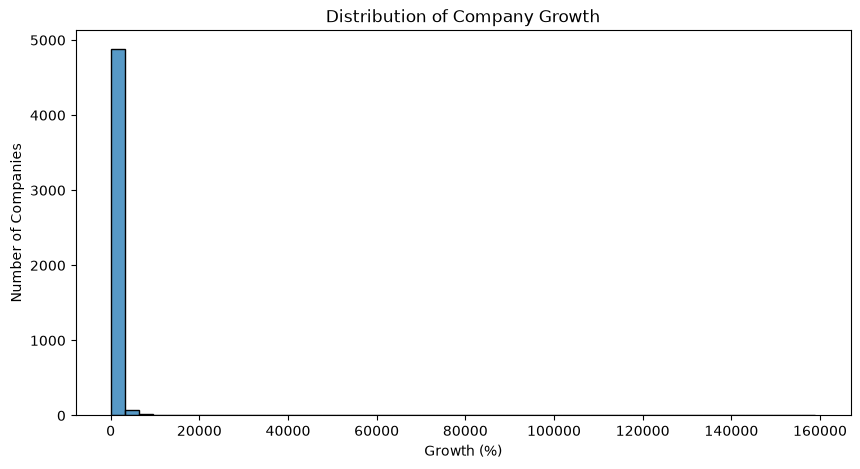

In [31]:
#histograma para visualizacion
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="growth", bins=50)

plt.title("Distribution of Company Growth")
plt.xlabel("Growth (%)")
plt.ylabel("Number of Companies")

plt.show()

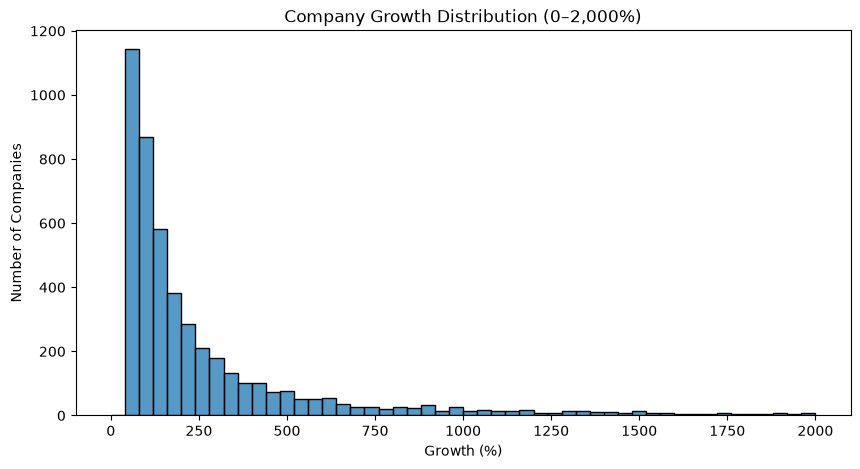

In [32]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="growth",
    bins=50,
    binrange=(0, 2000)
)

plt.title("Company Growth Distribution (0–2,000%)")
plt.xlabel("Growth (%)")
plt.ylabel("Number of Companies")

plt.show()


## Data Quality Assessment

Evaluating missing values, duplicate records, data types, and potential inconsistencies before cleaning the dataset.

In [33]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   _input         0 non-null      float64
 1   _num           5000 non-null   int64  
 2   _widgetName    5000 non-null   str    
 3   _source        5000 non-null   str    
 4   _resultNumber  5000 non-null   int64  
 5   _pageUrl       5000 non-null   str    
 6   id             5000 non-null   int64  
 7   rank           5000 non-null   int64  
 8   workers        5000 non-null   int64  
 9   company        5000 non-null   str    
 10  url            5000 non-null   str    
 11  state_l        5000 non-null   str    
 12  state_s        5000 non-null   str    
 13  city           5000 non-null   str    
 14  metro          4942 non-null   str    
 15  growth         5000 non-null   float64
 16  revenue        5000 non-null   int64  
 17  industry       5000 non-null   str    
 18  yrs_on_list    5000

In [34]:
df.isnull().sum()

_input           5000
_num                0
_widgetName         0
_source             0
_resultNumber       0
_pageUrl            0
id                  0
rank                0
workers             0
company             0
url                 0
state_l             0
state_s             0
city                0
metro              58
growth              0
revenue             0
industry            0
yrs_on_list         0
dtype: int64

In [ ]:
#eliminar las columnas que no dan informacion de las empresas, sino que son metadatos
columns_to_drop = [
    "_input",
    "_num",
    "_widgetName",
    "_source",
    "_resultNumber",
    "_pageUrl"
]

df = df.drop(columns=columns_to_drop)

df.head()

KeyError: "['_input', '_num', '_widgetName', '_source', '_resultNumber', '_pageUrl'] not found in axis"

In [39]:
print(f'New dimensions: {df.shape}')

New dimensions: (5000, 13)


In [45]:
print(df[["rank", "workers", "growth", "revenue", "yrs_on_list"]].describe())

#compañias con zero cosas
print("\nCompanies with zero workers:", (df["workers"] == 0).sum())

print("Companies with zero revenue:", (df["revenue"] == 0).sum())

print("Companies with zero growth:", (df["growth"] == 0).sum())

              rank       workers         growth       revenue  yrs_on_list
count  5000.000000   5000.000000    5000.000000  5.000000e+03  5000.000000
mean   2500.500000    208.969800     516.439892  4.305818e+07     2.744400
std    1443.520003   1074.600125    2786.061791  1.818559e+08     1.999067
min       1.000000      0.000000      42.447000  1.953000e+06     1.000000
25%    1250.750000     24.000000      84.208250  4.876791e+06     1.000000
50%    2500.500000     50.000000     151.722800  1.072208e+07     2.000000
75%    3750.250000    125.000000     347.652825  2.695213e+07     4.000000
max    5000.000000  34219.000000  158956.910600  5.528203e+09    12.000000

Companies with zero workers: 13
Companies with zero revenue: 0
Companies with zero growth: 0


In [47]:
#¿Cuales empresas tienen 0 trabajadores? 
zero_workers = df[df['workers'] == 0]

zero_workers[[
    "company",
    "industry",
    "state_l",
    "growth",
    "revenue",
    "workers"
]]

,company,industry,state_l,growth,revenue,workers
597,MileStone Community Builders,Real Estate,Texas,795.3091,88777494,0
1057,Fruitables Pet Food,Food & Beverage,Texas,419.4628,5022478,0
1243,GTN Technical Staffing,Human Resources,Texas,350.0197,21830995,0
1635,Subzero Engineering,Manufacturing,Utah,260.2377,9429145,0
2187,LabConnect,Health,Washington,181.3748,12878653,0
2922,Sorriso Technologies,Software,Massachusetts,124.2271,2919195,0
3174,Phydeaux,Retail,North Carolina,110.1436,6575960,0
3344,Health Advocate,Health,Pennsylvania,100.5489,86092370,0
4125,Automation & Control,Engineering,New Jersey,70.4912,7559026,0
4407,American Sensor Technologies,Manufacturing,New Jersey,61.2169,19722422,0


In [49]:
#copiar el df para mantener el original
df_clean = df.copy()

In [50]:
df_clean['workers'] = df['workers'].replace(0, np.nan)

print("Missing workers: ", df_clean["workers"].isnull().sum())

df_clean.isnull().sum()

Missing workers:  13


id              0
rank            0
workers        13
company         0
url             0
state_l         0
state_s         0
city            0
metro          58
growth          0
revenue         0
industry        0
yrs_on_list     0
dtype: int64

In [51]:
categorical_columns = ["company", "state_l", "state_s", "city", "metro", "industry"]

for column in categorical_columns:
    print(f"\n{column}:")
    print("Unique values:", df_clean[column].nunique())
    print("Empty strings:", (df_clean[column].astype("string").str.strip() == "").sum())


company:
Unique values: 5000
Empty strings: 0

state_l:
Unique values: 51
Empty strings: 0

state_s:
Unique values: 51
Empty strings: 0

city:
Unique values: 1352
Empty strings: 0

metro:
Unique values: 325
Empty strings: 0

industry:
Unique values: 25
Empty strings: 0


In [54]:
#comprobar que los nombres de las industrias sean consistentes
print(sorted(df_clean["industry"].unique()))

print(sorted(df_clean["state_l"].unique()))

print(sorted(df_clean["state_s"].unique()))

['Advertising & Marketing', 'Business Products & Services', 'Computer Hardware', 'Construction', 'Consumer Products & Services', 'Education', 'Energy', 'Engineering', 'Environmental Services', 'Financial Services', 'Food & Beverage', 'Government Services', 'Health', 'Human Resources', 'IT Services', 'Insurance', 'Logistics & Transportation', 'Manufacturing', 'Media', 'Real Estate', 'Retail', 'Security', 'Software', 'Telecommunications', 'Travel & Hospitality']
['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'District of Columbia', 'Florida', 'Georgia', 'Hawaii', 'Idaho', 'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana', 'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota', 'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada', 'New Hampshire', 'New Jersey', 'New Mexico', 'New York', 'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon', 'Pennsylvania', 'Puerto Rico', 'Rhode Island', 'South Carolina

In [ ]:
#ver si state1 y s sí concuerdan
state_mapping = (
    df_clean[["state_l", "state_s"]]
    .drop_duplicates()
    .sort_values("state_l")
)

print(state_mapping.to_string(index=False))

             state_l state_s
             Alabama      AL
              Alaska      AK
             Arizona      AZ
            Arkansas      AR
          California      CA
            Colorado      CO
         Connecticut      CT
            Delaware      DE
District of Columbia      DC
             Florida      FL
             Georgia      GA
              Hawaii      HI
               Idaho      ID
            Illinois      IL
             Indiana      IN
                Iowa      IA
              Kansas      KS
            Kentucky      KY
           Louisiana      LA
               Maine      ME
            Maryland      MD
       Massachusetts      MA
            Michigan      MI
           Minnesota      MN
         Mississippi      MS
            Missouri      MO
             Montana      MT
            Nebraska      NE
              Nevada      NV
       New Hampshire      NH
          New Jersey      NJ
          New Mexico      NM
            New York      NY
      North Ca

In [58]:
print(df_clean.info())

print(f'\n{df_clean.isnull().sum()}')

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           5000 non-null   int64  
 1   rank         5000 non-null   int64  
 2   workers      4987 non-null   float64
 3   company      5000 non-null   str    
 4   url          5000 non-null   str    
 5   state_l      5000 non-null   str    
 6   state_s      5000 non-null   str    
 7   city         5000 non-null   str    
 8   metro        4942 non-null   str    
 9   growth       5000 non-null   float64
 10  revenue      5000 non-null   int64  
 11  industry     5000 non-null   str    
 12  yrs_on_list  5000 non-null   int64  
dtypes: float64(2), int64(4), str(7)
memory usage: 507.9 KB
None

id              0
rank            0
workers        13
company         0
url             0
state_l         0
state_s         0
city            0
metro          58
growth          0
revenue         0
industry  

## 6. Exploration Summary

The initial exploration identified the dataset structure, numerical distributions, industry composition, and geographical characteristics.

The data quality assessment revealed:
- Six unnecessary metadata columns.
- 58 missing values in the metro column.
- 13 records with zero workers, treated as missing values.
- No duplicated rows, IDs, or company names.
- No empty categorical values.

The dataset contains 5,000 company records and 13 relevant columns after removing metadata.

Further data cleaning and preparation will be performed in the next stage.